# Backtest con costos: fuga de información, frecuencia de rebalanceo y punto de equilibrio de costos

**Perfil:** Gestión de portafolios  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un backtest puede mentir de dos maneras: usando información que no existía (**fuga**) y olvidando lo que cuesta operar. ¿Cuánto infla el Sharpe una fuga pequeña, y cómo se detecta? ¿Cuánto cuesta rebalancear más seguido, y a partir de qué costo deja de convenir una estrategia con señal real?

## Recorrido

1. Mundo sintético con una señal de **tendencia real pero modesta** y estrategias simples (pesos iguales, volatilidad inversa, momentum).
2. **Versión 1:** backtest bruto, sin costos.
3. **La fuga de información:** una versión con un desfase mal puesto, su efecto y una prueba de desfase que la delata.
4. **Versión 2:** costos de transacción; frecuencia de rebalanceo y bandas de no-operación.
5. **Punto de equilibrio:** el costo en el que la estrategia pierde su ventaja.
6. Incertidumbre entre historias, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats

## 2. El mundo simulado

Ocho activos, 15 años de datos diarios (3.780 días). Los retornos tienen un **factor de mercado** común y ruido idiosincrático. Además, cada activo tiene un **componente de tendencia lento** (autorregresivo mensual, $\rho=0{,}9$, con desvío estacionario de **12 % anual**) que mueve su retorno esperado: es la única fuente real de predictibilidad. Esa señal es **modesta a propósito**: el objetivo es ver si sobrevive a los costos.

> *Nota de calibración:* una primera versión usaba unidades equivocadas para la tendencia (la trataba como retorno mensual y la multiplicaba por 12/252 como si fuera anual) y producía una tendencia de ~30 % anual. El momentum alcanzaba un Sharpe de 1,36, ganaba a pesos iguales en el 100 % de las historias y el punto de equilibrio de costos nunca se cruzaba: la señal no era modesta. Se corrigieron las unidades y se calibró la amplitud para que la ventaja bruta sea real pero pequeña.

In [2]:
N_A, T_DIAS = 8, 252 * 15
MU = np.array([0.050, 0.055, 0.060, 0.065, 0.070, 0.075, 0.080, 0.085])
BETA = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.0, 1.1, 1.2])
VOL_ID = np.array([0.008, 0.009, 0.009, 0.010, 0.010, 0.011, 0.011, 0.012])
RHO = 0.90
SIG_TENDENCIA = 0.12                         # desvio ESTACIONARIO de la tendencia, en unidades de retorno ANUAL
S_TREND = SIG_TENDENCIA * np.sqrt(1 - RHO ** 2)   # desvio de la innovacion mensual
RF = 0.02

def simular(seed, T=T_DIAS, s_trend=S_TREND):
    rg = np.random.default_rng(seed); n_mes = T // 21 + 1
    m = np.zeros((n_mes, N_A))
    for k in range(1, n_mes): m[k] = RHO * m[k - 1] + rg.normal(0, s_trend, N_A)
    tendencia = np.repeat(m, 21, axis=0)[:T]
    f = rg.normal(0, 0.14 / np.sqrt(252), T)
    eps = rg.normal(0, 1, (T, N_A)) * VOL_ID
    return (MU + tendencia) / 252 + f[:, None] * BETA + eps                 # retorno diario = (media anual + tendencia anual) / 252 + mercado + ruido

R0 = simular(1)
print(R0.shape, "| vol anual del mercado ~", f"{R0.mean(1).std() * np.sqrt(252):.3f}", "| retorno anual medio por activo:", np.round(R0.mean(0) * 252, 3))

(3780, 8) | vol anual del mercado ~ 0.141 | retorno anual medio por activo: [-0.004 -0.037  0.042  0.003  0.012  0.098  0.013 -0.053]


## 3. El motor del backtest

Reglas que evitan fugas **por construcción**:

1. Los **pesos objetivo** de la fecha $t$ se calculan solo con datos **hasta $t-1$**: `R[:t]` (el corte excluye el día $t$).
2. El retorno del día $t$ se obtiene con los pesos fijados al inicio del día.
3. Entre rebalanceos los pesos **derivan** con los retornos.
4. El costo es proporcional al **turnover** del rebalanceo: $c\cdot\sum_i|w^*_i-w_i|$.

Un parámetro `fuga` (días) permite **romper la regla 1 a propósito** para estudiar la fuga.

In [3]:
WARM = 252

def objetivo_ew(H): return np.full(N_A, 1 / N_A)

def objetivo_iv(H, v=63):
    s = H[-v:].std(axis=0); w = 1 / s; return w / w.sum()

def objetivo_mom(H, ventana=126, k=3):
    señal = H[-ventana:].sum(axis=0); top = np.argsort(señal)[-k:]; w = np.zeros(N_A); w[top] = 1 / k; return w

def correr(R, objetivo, frec=21, costo_bps=0.0, fuga=0, banda=None):
    T = len(R); w = np.full(N_A, 1 / N_A); ret = np.zeros(T - WARM); turn = 0.0; objetivo_w = w.copy(); c = costo_bps / 1e4
    for t in range(WARM, T):
        costo_dia = 0.0
        if banda is None: toca = (t - WARM) % frec == 0
        else: toca = (t == WARM) or (np.abs(w - objetivo_w).max() > banda)
        if toca:
            objetivo_w = objetivo(R[:t + fuga]) if fuga > 0 else objetivo(R[:t])      # R[:t] = datos hasta t-1; con fuga, ve 'fuga' dias del futuro
            trade = np.abs(objetivo_w - w).sum(); costo_dia = c * trade; turn += trade; w = objetivo_w.copy()
        r = w @ R[t]; ret[t - WARM] = r - costo_dia
        w = w * (1 + R[t]) / (1 + r)
    anios = (T - WARM) / 252
    return ret, turn / anios / 2                     # retorno diario neto; turnover unilateral anual

def stats_(r):
    a = r.mean() * 252; v = r.std(ddof=1) * np.sqrt(252); return {"retorno": a, "vol": v, "sharpe": (a - RF) / v}

# prueba de la funcion: pesos iguales con rebalanceo diario y sin costos ~ promedio simple de retornos (salvo deriva intradia nula)
r_ew, t_ew = correr(R0, objetivo_ew, frec=1)
assert np.allclose(r_ew, R0[WARM:].mean(axis=1), atol=1e-12), "EW rebalanceado a diario debe igualar el promedio simple"
print("EW rebalanceado a diario reproduce el promedio simple de retornos. Turnover anual:", round(t_ew, 3))

EW rebalanceado a diario reproduce el promedio simple de retornos. Turnover anual: 0.948


## 4. Versión 1: backtest bruto

Tres estrategias, rebalanceo mensual (21 días), **sin costos**. Se repite en 60 historias independientes para tener una estimación estable y se muestran la **media** y su **error estándar**.

In [4]:
HIST = [simular(100 + i) for i in range(60)]
ESTRAT = {"pesos iguales": objetivo_ew, "vol inversa": objetivo_iv, "momentum (126d, top 3)": objetivo_mom}

def correr_todas(frec=21, costo_bps=0.0, fuga=0, banda=None, hist=HIST):
    filas = []
    for i, R in enumerate(hist):
        for nombre, f in ESTRAT.items():
            r, tn = correr(R, f, frec=frec, costo_bps=costo_bps, fuga=fuga, banda=banda); s = stats_(r)
            filas.append({"hist": i, "estrategia": nombre, "turnover": tn, **s})
    return pd.DataFrame(filas)

bruto = correr_todas()
def resumen(df):
    g = df.groupby("estrategia").agg(sharpe=("sharpe", "mean"), sharpe_ee=("sharpe", lambda s: s.std() / np.sqrt(len(s))), retorno=("retorno", "mean"), vol=("vol", "mean"), turnover=("turnover", "mean"))
    return g
res_bruto = resumen(bruto); res_bruto.round(3)

,sharpe,sharpe_ee,retorno,vol,turnover
estrategia,,,,,
"momentum (126d, top 3)",0.5110,0.0360,0.1010,0.1590,2.9120
pesos iguales,0.3040,0.0360,0.0620,0.1390,0.2130
vol inversa,0.3080,0.0360,0.0620,0.1350,0.3750


In [5]:
mom, ew = bruto[bruto.estrategia == "momentum (126d, top 3)"].set_index("hist")["sharpe"], bruto[bruto.estrategia == "pesos iguales"].set_index("hist")["sharpe"]
dif = (mom - ew); ic = (dif.mean() - 1.96 * dif.std() / np.sqrt(len(dif)), dif.mean() + 1.96 * dif.std() / np.sqrt(len(dif)))
print("Lectura (bruto, sin costos):")
print(f"  Sharpe medio: pesos iguales {ew.mean():.3f} | momentum {mom.mean():.3f}. Diferencia momentum - EW = {dif.mean():+.3f} (IC95% [{ic[0]:+.3f}, {ic[1]:+.3f}]); momentum gana en {(dif > 0).mean():.0%} de las historias.")
print(f"  Turnover anual (unilateral): EW {res_bruto.loc['pesos iguales', 'turnover']:.2f} | vol inversa {res_bruto.loc['vol inversa', 'turnover']:.2f} | momentum {res_bruto.loc['momentum (126d, top 3)', 'turnover']:.2f}.")

Lectura (bruto, sin costos):
  Sharpe medio: pesos iguales 0.304 | momentum 0.511. Diferencia momentum - EW = +0.207 (IC95% [+0.171, +0.244]); momentum gana en 88% de las historias.
  Turnover anual (unilateral): EW 0.21 | vol inversa 0.38 | momentum 2.91.


## 5. La fuga de información

Error típico: calcular la señal con datos que incluyen el período que se va a operar (un *off-by-one* a escala mensual). Se simula con `fuga=21`: el momentum "ve" 21 días del futuro (1/6 de su ventana de 126 días).

In [6]:
def sharpe_medio(frec=21, fuga=0, nombre="momentum (126d, top 3)", n=30):
    s = []
    for R in HIST[:n]:
        r, _ = correr(R, ESTRAT[nombre], frec=frec, fuga=fuga); s.append(stats_(r)["sharpe"])
    return np.mean(s), np.std(s) / np.sqrt(len(s))

limpio = sharpe_medio(fuga=0); con_fuga = sharpe_medio(fuga=21)
print(f"Sharpe del momentum SIN fuga: {limpio[0]:.3f} (+-{limpio[1]:.3f}) | CON fuga de 21 dias: {con_fuga[0]:.3f} (+-{con_fuga[1]:.3f})")
print(f"La fuga multiplica el Sharpe por {con_fuga[0] / limpio[0]:.1f}x.")

Sharpe del momentum SIN fuga: 0.509 (+-0.056) | CON fuga de 21 dias: 1.706 (+-0.047)
La fuga multiplica el Sharpe por 3.4x.


### 5.1 Una prueba de desfase que delata la fuga

Si la señal es **legítima**, retrasarla (calcular el objetivo con datos más viejos) debe **degradar** el resultado **gradualmente**, porque la tendencia es persistente. Si hay **fuga**, el rendimiento viene de ver el futuro: al retrasar la señal más allá de lo que se "espiaba", el resultado **colapsa** a la parte genuina. Se mide el Sharpe del momentum con una señal retrasada $\ell$ días (se calcula con datos hasta $t-1-\ell$), con y sin fuga.

In [7]:
def objetivo_retrasado(base, retraso):
    # senal calculada con datos mas viejos: se descartan los ultimos 'retraso' dias disponibles
    return (lambda H: base(H[:-retraso] if retraso > 0 else H))

def sharpe_con_retraso(retraso, fuga, n=30):
    s = []
    for R in HIST[:n]:
        r, _ = correr(R, objetivo_retrasado(objetivo_mom, retraso), frec=21, fuga=fuga); s.append(stats_(r)["sharpe"])
    return np.mean(s)

retrasos = [0, 5, 10, 21, 42, 63]
curva = pd.DataFrame({"sin fuga": [sharpe_con_retraso(l, 0) for l in retrasos], "con fuga (21 dias)": [sharpe_con_retraso(l, 21) for l in retrasos]}, index=retrasos)
curva.index.name = "retraso de la senal (dias)"
curva.round(3)

,sin fuga,con fuga (21 dias)
retraso de la senal (dias),,
0,0.5090,1.7060
5,0.4990,1.4210
10,0.4830,1.1500
21,0.5020,0.5090
42,0.4920,0.5020
63,0.4490,0.4920


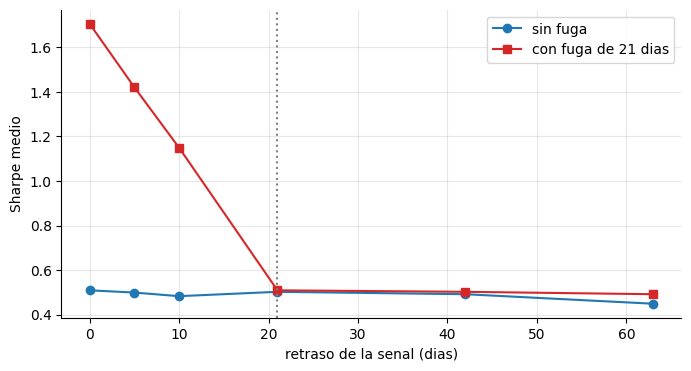

Lectura:
  Retrasar la senal 21 dias reduce el Sharpe en 0.007 sin fuga y en 1.197 con fuga.
  Con fuga, el Sharpe cae 70% al retrasar 21 dias; sin fuga, 1%.
  Regla practica: si un pequeno retraso de la senal destruye casi todo el rendimiento, probablemente se estaba usando informacion futura.


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva.index, curva["sin fuga"], "o-", label="sin fuga"); ax.plot(curva.index, curva["con fuga (21 dias)"], "s-", color="C3", label="con fuga de 21 dias")
ax.axvline(21, color="gray", ls=":"); ax.set_xlabel("retraso de la senal (dias)"); ax.set_ylabel("Sharpe medio"); ax.legend(); plt.show()
caida_sf = curva.loc[0, "sin fuga"] - curva.loc[21, "sin fuga"]; caida_cf = curva.loc[0, "con fuga (21 dias)"] - curva.loc[21, "con fuga (21 dias)"]
print("Lectura:")
print(f"  Retrasar la senal 21 dias reduce el Sharpe en {caida_sf:.3f} sin fuga y en {caida_cf:.3f} con fuga.")
print(f"  Con fuga, el Sharpe cae {(1 - curva.loc[21, 'con fuga (21 dias)'] / curva.loc[0, 'con fuga (21 dias)']) * 100:.0f}% al retrasar 21 dias; sin fuga, {(1 - curva.loc[21, 'sin fuga'] / curva.loc[0, 'sin fuga']) * 100:.0f}%.")
print("  Regla practica: si un pequeno retraso de la senal destruye casi todo el rendimiento, probablemente se estaba usando informacion futura.")

## 6. Versión 2: costos de transacción

Se descuenta un costo proporcional al **turnover** del rebalanceo (por ejemplo, 10 pb por unidad de nocional operada). Se compara el **Sharpe neto** a distintas frecuencias de rebalanceo.

In [9]:
FRECS = {"semanal (5d)": 5, "mensual (21d)": 21, "trimestral (63d)": 63, "anual (252d)": 252}
filas = []
for nombre_f, fr in FRECS.items():
    df = correr_todas(frec=fr, costo_bps=10.0, hist=HIST[:30])
    for est, g in df.groupby("estrategia"):
        filas.append({"frecuencia": nombre_f, "estrategia": est, "sharpe_neto": g["sharpe"].mean(), "turnover": g["turnover"].mean()})
freq = pd.DataFrame(filas)
freq.pivot(index="frecuencia", columns="estrategia", values="sharpe_neto").loc[list(FRECS)].round(3)

estrategia,"momentum (126d, top 3)",pesos iguales,vol inversa
frecuencia,,,
semanal (5d),0.4360,0.2700,0.2690
mensual (21d),0.4720,0.2760,0.2770
trimestral (63d),0.4850,0.2850,0.2880
anual (252d),0.4040,0.3090,0.3100


In [10]:
print("Turnover anual unilateral por frecuencia y estrategia:")
print(freq.pivot(index="frecuencia", columns="estrategia", values="turnover").loc[list(FRECS)].round(2).to_string())
pt = freq.pivot(index="frecuencia", columns="estrategia", values="sharpe_neto")
print()
print("Lectura (10 pb de costo):")
for e in pt.columns:
    mejor = pt[e].idxmax(); print(f"  {e:24s}: la mejor frecuencia es '{mejor}' (Sharpe neto {pt.loc[mejor, e]:.3f}); la peor, '{pt[e].idxmin()}' ({pt[e].min():.3f}).")

Turnover anual unilateral por frecuencia y estrategia:
estrategia        momentum (126d, top 3)  pesos iguales  vol inversa
frecuencia                                                          
semanal (5d)                      6.3200         0.4300       0.7500
mensual (21d)                     2.9100         0.2100       0.3800
trimestral (63d)                  1.6200         0.1300       0.2200
anual (252d)                      0.6100         0.0700       0.0800

Lectura (10 pb de costo):
  momentum (126d, top 3)  : la mejor frecuencia es 'trimestral (63d)' (Sharpe neto 0.485); la peor, 'anual (252d)' (0.404).
  pesos iguales           : la mejor frecuencia es 'anual (252d)' (Sharpe neto 0.309); la peor, 'semanal (5d)' (0.270).
  vol inversa             : la mejor frecuencia es 'anual (252d)' (Sharpe neto 0.310); la peor, 'semanal (5d)' (0.269).


### 6.1 Bandas de no-operación

En lugar de rebalancear por calendario, se rebalancea **solo si algún peso se aleja más de una banda** de su objetivo. Reduce el turnover de las estrategias de pesos fijos.

In [11]:
filas = []
for banda in (None, 0.02, 0.05, 0.10):
    neto = correr_todas(frec=21, costo_bps=10.0, banda=banda, hist=HIST[:30]); bruto_b = correr_todas(frec=21, costo_bps=0.0, banda=banda, hist=HIST[:30])
    g, gb = neto[neto.estrategia == "pesos iguales"], bruto_b[bruto_b.estrategia == "pesos iguales"]
    filas.append({"banda": "calendario mensual" if banda is None else f"{banda:.0%}", "sharpe_neto_EW": g["sharpe"].mean(), "sharpe_bruto_EW": gb["sharpe"].mean(), "turnover_EW": g["turnover"].mean()})
bandas = pd.DataFrame(filas).set_index("banda")
bandas["ahorro_por_costos"] = bandas["sharpe_neto_EW"] - bandas["sharpe_bruto_EW"]
bandas.round(3)

,sharpe_neto_EW,sharpe_bruto_EW,turnover_EW,ahorro_por_costos
banda,,,,
calendario mensual,0.2760,0.2790,0.2130,-0.0030
2%,0.2850,0.2870,0.1210,-0.0020
5%,0.3110,0.3120,0.0610,-0.0010
10%,0.3320,0.3320,0.0350,-0.0010


In [12]:
base = bandas.loc["calendario mensual"]
print("Lectura: efecto de las bandas sobre pesos iguales (10 pb de costo).")
for banda in bandas.index[1:]:
    f = bandas.loc[banda]
    mejora_neta = f["sharpe_neto_EW"] - base["sharpe_neto_EW"]; cambio_bruto = f["sharpe_bruto_EW"] - base["sharpe_bruto_EW"]
    print(f"  banda {banda:>4s}: Sharpe neto {mejora_neta:+.3f} vs calendario, de los cuales {cambio_bruto:+.3f} ya aparecen SIN costos (bruto) y {mejora_neta - cambio_bruto:+.3f} son ahorro de costos.")
print("  Casi toda la mejora NO es ahorro de costos: dejar derivar los pesos deja correr a los activos ganadores, un efecto de seguimiento de tendencia IMPLICITO que existe porque este mundo tiene tendencias reales.")
print("  Una banda no es gratuita: cambia el perfil de la estrategia; hay que separar el efecto costos del efecto de cartera.")

Lectura: efecto de las bandas sobre pesos iguales (10 pb de costo).
  banda   2%: Sharpe neto +0.009 vs calendario, de los cuales +0.008 ya aparecen SIN costos (bruto) y +0.001 son ahorro de costos.
  banda   5%: Sharpe neto +0.035 vs calendario, de los cuales +0.033 ya aparecen SIN costos (bruto) y +0.002 son ahorro de costos.
  banda  10%: Sharpe neto +0.055 vs calendario, de los cuales +0.053 ya aparecen SIN costos (bruto) y +0.003 son ahorro de costos.
  Casi toda la mejora NO es ahorro de costos: dejar derivar los pesos deja correr a los activos ganadores, un efecto de seguimiento de tendencia IMPLICITO que existe porque este mundo tiene tendencias reales.
  Una banda no es gratuita: cambia el perfil de la estrategia; hay que separar el efecto costos del efecto de cartera.


## 7. El punto de equilibrio de costos

¿A qué costo el momentum deja de valer la pena **frente a pesos iguales** (que opera muy poco)? Se barre el costo y se mide la diferencia de Sharpe neto (momentum − EW), con rebalanceo mensual.

In [13]:
filas = []
for c in (0, 5, 10, 20, 40, 80):
    df = correr_todas(frec=21, costo_bps=float(c), hist=HIST[:30])
    m_ = df[df.estrategia == "momentum (126d, top 3)"].set_index("hist")["sharpe"]; e_ = df[df.estrategia == "pesos iguales"].set_index("hist")["sharpe"]
    d_ = m_ - e_; filas.append({"costo_pb": c, "sharpe_mom": m_.mean(), "sharpe_EW": e_.mean(), "dif": d_.mean(), "dif_ee": d_.std() / np.sqrt(len(d_)), "mom_gana_%": (d_ > 0).mean() * 100})
be = pd.DataFrame(filas).set_index("costo_pb")
be.round(3)

,sharpe_mom,sharpe_EW,dif,dif_ee,mom_gana_%
costo_pb,,,,,
0,0.5090,0.2790,0.2300,0.0260,90.0000
5,0.4910,0.2780,0.2130,0.0260,86.6670
10,0.4720,0.2760,0.1960,0.0260,83.3330
20,0.4360,0.2730,0.1620,0.0260,83.3330
40,0.3620,0.2670,0.0950,0.0270,76.6670
80,0.2150,0.2550,-0.0400,0.0280,50.0000


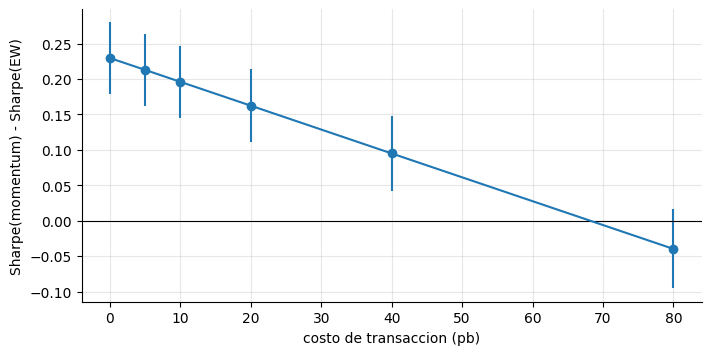

Lectura:
  Sin costos, momentum supera a EW en +0.230 de Sharpe. A 80 pb la diferencia es -0.040.
  Punto de equilibrio (interpolado): ~68 pb.
  El turnover de momentum (2.9x al anio) es muchas veces el de EW (0.21x): por eso es tan sensible al costo.


In [14]:
cruce = None
for a, b in zip(be.index[:-1], be.index[1:]):
    if be.loc[a, "dif"] > 0 >= be.loc[b, "dif"]:
        cruce = a + (b - a) * be.loc[a, "dif"] / (be.loc[a, "dif"] - be.loc[b, "dif"])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(be.index, be["dif"], yerr=1.96 * be["dif_ee"], fmt="o-"); ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("costo de transaccion (pb)"); ax.set_ylabel("Sharpe(momentum) - Sharpe(EW)"); plt.show()
print("Lectura:")
print(f"  Sin costos, momentum supera a EW en {be.loc[0, 'dif']:+.3f} de Sharpe. A 80 pb la diferencia es {be.loc[80, 'dif']:+.3f}.")
print(f"  Punto de equilibrio (interpolado): {'~' + f'{cruce:.0f} pb' if cruce is not None else 'no se cruza en el rango probado'}.")
print(f"  El turnover de momentum ({res_bruto.loc['momentum (126d, top 3)', 'turnover']:.1f}x al anio) es muchas veces el de EW ({res_bruto.loc['pesos iguales', 'turnover']:.2f}x): por eso es tan sensible al costo.")

## 8. Pruebas automáticas

In [15]:
# 8.1 el motor: EW diario = promedio simple (verificado arriba); los pesos siempre suman 1 y sin costos el retorno es el de la cartera
w_ = np.full(N_A, 1 / N_A)
for t in range(300, 340):
    r_ = w_ @ R0[t]; w_n = w_ * (1 + R0[t]) / (1 + r_); assert abs(w_n.sum() - 1) < 1e-12; w_ = w_n
# 8.2 sin fuga, el objetivo en t no depende de datos en t o posteriores: cambiar R[t:] no cambia R[:t]
Rm = R0.copy(); Rm[1000:, :] += 0.5
assert np.allclose(objetivo_mom(R0[:1000]), objetivo_mom(Rm[:1000]))
# 8.3 los costos reducen el retorno: neto <= bruto en cada historia (turnover >= 0)
r_b, _ = correr(R0, objetivo_mom, frec=21, costo_bps=0); r_n, _ = correr(R0, objetivo_mom, frec=21, costo_bps=25)
assert r_n.sum() < r_b.sum() and (r_b - r_n).min() >= -1e-15
# 8.4 el costo total ~ costo unitario x turnover: la perdida de retorno anual es proporcional al costo
d1 = (correr(R0, objetivo_mom, 21, 0)[0].mean() - correr(R0, objetivo_mom, 21, 10)[0].mean()) * 252
d2 = (correr(R0, objetivo_mom, 21, 0)[0].mean() - correr(R0, objetivo_mom, 21, 20)[0].mean()) * 252
assert abs(d2 / d1 - 2) < 0.02
# 8.5 la fuga infla el Sharpe de forma enorme y el retraso de la senal la delata
assert con_fuga[0] > 2 * limpio[0]
assert caida_cf > 2 * max(caida_sf, 0.05)
assert curva.loc[21, "con fuga (21 dias)"] < 0.6 * curva.loc[0, "con fuga (21 dias)"]
# 8.6 el momentum tiene senal real (gana a EW en bruto) pero mucho mas turnover
assert dif.mean() > 0 and res_bruto.loc["momentum (126d, top 3)", "turnover"] > 5 * res_bruto.loc["pesos iguales", "turnover"]
# 8.7 mas frecuencia, mas turnover y mas costo; con costos, el momentum prefiere rebalancear menos que semanalmente
tf = freq.pivot(index="frecuencia", columns="estrategia", values="turnover").loc[list(FRECS)]
assert (tf["momentum (126d, top 3)"].diff().dropna() < 0).all()
assert pt.loc["mensual (21d)", "momentum (126d, top 3)"] > pt.loc["semanal (5d)", "momentum (126d, top 3)"]
# 8.8 las bandas reducen el turnover de EW respecto del calendario mensual
assert bandas.iloc[1:]["turnover_EW"].max() < bandas.loc["calendario mensual", "turnover_EW"]
# 8.8b la mejora de las bandas viene sobre todo del efecto de cartera (bruto), no del ahorro de costos
assert (bandas.iloc[1:]["sharpe_bruto_EW"] - bandas.loc["calendario mensual", "sharpe_bruto_EW"]).min() > 0
assert (bandas.iloc[1:]["ahorro_por_costos"] - bandas.loc["calendario mensual", "ahorro_por_costos"]).abs().max() < 0.03
# 8.9 la ventaja del momentum cae al subir el costo y cruza cero dentro del rango
assert be["dif"].is_monotonic_decreasing and be.loc[0, "dif"] > 0 and be.loc[80, "dif"] < 0
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: backtest bruto | El momentum supera a pesos iguales en Sharpe gracias a la tendencia real del generador, con un turnover muy superior | Ver siempre el turnover junto al Sharpe |
| Fuga de información | Ver 21 días del futuro multiplica el Sharpe por ≈ 3,4 (0,51 → 1,71) | Tratar un Sharpe espectacular como sospecha, no como hallazgo |
| Prueba de desfase | Retrasar la señal 21 días degrada un 1 % el Sharpe de la versión limpia y un 70 % el de la versión con fuga | Incluir la prueba de desfase en todo backtest |
| v2: costos | El turnover del momentum lo hace muy sensible al costo; la frecuencia de rebalanceo importa | Optimizar la frecuencia con los costos reales |
| Bandas de no-operación | Reducen el turnover de pesos iguales, pero casi toda la mejora de Sharpe viene del efecto de cartera (dejar correr ganadores) y no del ahorro de costos | Separar el efecto de cartera del efecto de costos antes de atribuir una mejora |
| Punto de equilibrio | La ventaja del momentum sobre pesos iguales (+0,21 de Sharpe bruto) desaparece a ≈ 68 pb de costo | Calcular el costo en que la estrategia deja de convenir |

**Límites que no deben ocultarse**

- La señal de tendencia es un componente autorregresivo del generador; en datos reales la predictibilidad es más débil, inestable y a veces inexistente.
- El costo es proporcional al turnover y constante; el costo real depende del tamaño operado, la liquidez y el estado del mercado.
- Solo se simulan 60 historias de 15 años; el error estándar de las diferencias de Sharpe sigue siendo apreciable (ver los IC).
- No se consideran impuestos, restricciones de apalancamiento ni impacto de mercado.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.